In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

In [2]:
x = np.kron(np.ones((1000,1)), np.arange(1000).reshape(1,1000))
y = x.T.copy()
xy = np.stack([y[:,:],x[:,:]], axis=2)

In [3]:
np.linalg.norm(np.array([[300,300],  [400, 700], [750,500]]) - xy[34,812], axis=1)

array([576.97486947, 382.75318418, 781.02496759])

In [4]:
wells = np.array([[300,300],  [400, 700], [750,500]])
weights = np.array([0.2,.6,.3])
def f(_xy):
    return np.sum(weights*np.log(np.linalg.norm((wells - _xy), axis=1)))

f3D = np.vectorize(f, signature='(m,n,k)->(m,n)')

In [5]:
z = np.zeros(x.shape)
for well, weight in zip(wells,weights):
    tmp = np.linalg.norm(xy - well, axis=2)
    z += np.where(tmp<=10, np.log(weight*5), np.log(weight*tmp))

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_7657/3056564614.py:4: RuntimeWarning: divide by zero encountered in log
  z += np.where(tmp<=10, np.log(weight*5), np.log(weight*tmp))


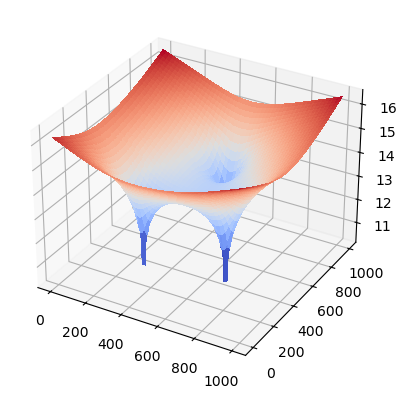

In [ ]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.plot_surface(x, y, z, cmap=cm.coolwarm, linewidth=0, antialiased=False)
# plt.savefig('../../Paper/figures/depression_cones3D.svg', format='svg')

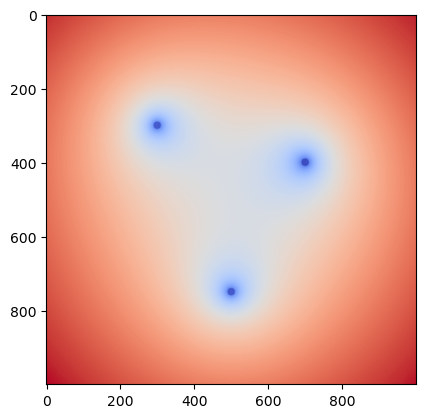

In [7]:
plt.imshow(z, cmap=cm.coolwarm)

In [8]:
from scipy import ndimage

z_avg = ndimage.uniform_filter(z, size=(100,100))[::100, ::100]

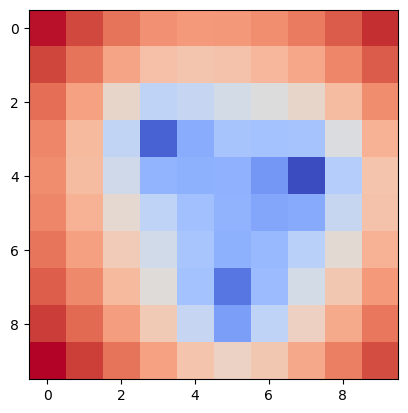

In [9]:
plt.imshow(z_avg, cmap=cm.coolwarm)

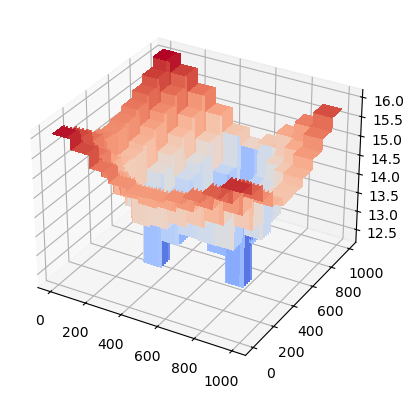

In [ ]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.plot_surface(x, y, np.kron(z_avg, np.ones((100,100))), cmap=cm.coolwarm, linewidth=0, antialiased=False)
# plt.savefig('../../Paper/figures/discretized_cones3D.svg', format='svg')